# Machine Learning Assignment 2 — End-to-End Classification

**Student:** Yaythish Kannaa G S  
**BITS ID:** 2026AJ05374  
**Dataset:** Breast Cancer Wisconsin (Diagnostic), available through scikit-learn.

This notebook includes dataset loading, inspection, preprocessing, stratified train/test splitting, training and evaluation of five classification models, visualizations, and artifact export. The held-out test set is not used to fit preprocessing steps or models.


## 1. Imports and output folders

In [1]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, roc_auc_score, precision_score, recall_score,
    f1_score, matthews_corrcoef, confusion_matrix,
    ConfusionMatrixDisplay, classification_report
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

RANDOM_STATE = 42
TEST_SIZE = 0.20
OUTPUT_DIR = Path("assignment_outputs")
MODEL_DIR = OUTPUT_DIR / "model"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
print("Output folder:", OUTPUT_DIR.resolve())


Output folder: /content/assignment_outputs


## 2. Dataset collection / loading

In [2]:
# This dataset is packaged with scikit-learn; no external download is required.
# Target mapping: 0 = malignant, 1 = benign.
dataset = load_breast_cancer(as_frame=True)
X = dataset.data.copy()
y = dataset.target.copy().rename("target")
df = X.copy()
df["target"] = y

print("Dataset: Breast Cancer Wisconsin (Diagnostic)")
print("Rows:", df.shape[0], "| Input features:", X.shape[1])
print("Target classes:", dict(enumerate(dataset.target_names)))
display(df.head())


Dataset: Breast Cancer Wisconsin (Diagnostic)
Rows: 569 | Input features: 30
Target classes: {0: np.str_('malignant'), 1: np.str_('benign')}


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


## 3. Data inspection and quality checks

In [3]:
print("Dataset shape:", df.shape)
print("\\nData types:")
display(df.dtypes.value_counts().rename("column_count").to_frame())
print("\\nMissing values:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_count"))
print("\\nDuplicate rows:", int(df.duplicated().sum()))
print("\\nClass counts:")
display(y.value_counts().sort_index().rename(index={0: "malignant (0)", 1: "benign (1)"}).to_frame("count"))
print("\\nFeature statistics:")
display(X.describe().T)


Dataset shape: (569, 31)
\nData types:


,column_count
float64,30
int64,1


\nMissing values:


,missing_count
mean radius,0
mean texture,0
mean perimeter,0
mean area,0
mean smoothness,0
mean compactness,0
mean concavity,0
mean concave points,0
mean symmetry,0
mean fractal dimension,0


\nDuplicate rows: 0
\nClass counts:


,count
target,
malignant (0),212
benign (1),357


\nFeature statistics:


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


## 4. Preprocessing and train/test split

All features are numeric. The notebook checks for missing values and uses a stratified 80/20 split. StandardScaler is fitted on the training data only through pipelines for Logistic Regression, KNN, and SVM. Decision Tree and Gaussian Naive Bayes use unscaled features.


In [4]:
if X.isna().any().any() or y.isna().any():
    raise ValueError("Missing values found; add an imputation step before fitting.")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)

print("Training rows:", len(X_train), "| Test rows:", len(X_test))
print("Training class proportions:")
display(y_train.value_counts(normalize=True).sort_index().to_frame("proportion"))
print("Test class proportions:")
display(y_test.value_counts(normalize=True).sort_index().to_frame("proportion"))


Training rows: 455 | Test rows: 114
Training class proportions:


,proportion
target,
0,0.373626
1,0.626374


Test class proportions:


,proportion
target,
0,0.368421
1,0.631579


## 5. Define five classification models

In [5]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))
    ]),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "K-Nearest Neighbors": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(n_neighbors=5))
    ]),
    "Gaussian Naive Bayes": GaussianNB(),
    "Support Vector Machine": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE))
    ])
}
for model_name, estimator in models.items():
    print(model_name, "->", estimator)


Logistic Regression -> Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier',
                 LogisticRegression(max_iter=5000, random_state=42))])
Decision Tree -> DecisionTreeClassifier(random_state=42)
K-Nearest Neighbors -> Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier', KNeighborsClassifier())])
Gaussian Naive Bayes -> GaussianNB()
Support Vector Machine -> Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier', SVC(probability=True, random_state=42))])


## 6. Train and evaluate models

In [6]:
results = []
fitted_models = {}

for model_name, model in models.items():
    model.fit(X_train, y_train)
    fitted_models[model_name] = model
    y_pred = model.predict(X_test)
    y_score = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "AUC": roc_auc_score(y_test, y_score),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "MCC": matthews_corrcoef(y_test, y_pred)
    })

metrics_df = pd.DataFrame(results).sort_values("Accuracy", ascending=False).reset_index(drop=True)
display(metrics_df.style.format({c: "{:.4f}" for c in metrics_df.columns if c != "Model"}))


,Model,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.9825,0.9954,0.9861,0.9861,0.9861,0.9623
1,Support Vector Machine,0.9825,0.9950,0.9861,0.9861,0.9861,0.9623
2,K-Nearest Neighbors,0.9561,0.9788,0.9589,0.9722,0.9655,0.9054
3,Gaussian Naive Bayes,0.9386,0.9878,0.9452,0.9583,0.9517,0.8676
4,Decision Tree,0.9123,0.9157,0.9559,0.9028,0.9286,0.8174


## 7. Compare model metrics visually

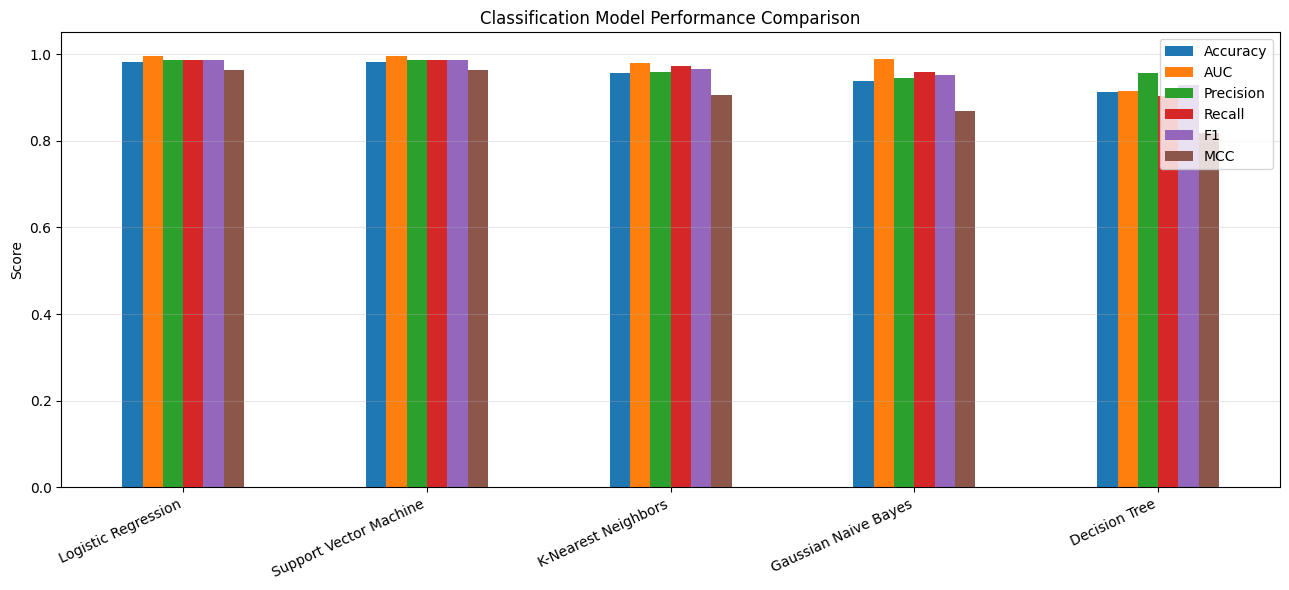

In [7]:
metric_columns = ["Accuracy", "AUC", "Precision", "Recall", "F1", "MCC"]
ax = metrics_df.set_index("Model")[metric_columns].plot(
    kind="bar", figsize=(13, 6), ylim=(0, 1.05)
)
ax.set_title("Classification Model Performance Comparison")
ax.set_ylabel("Score")
ax.set_xlabel("")
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


## 8. Confusion matrices and classification reports

\nLogistic Regression
               precision    recall  f1-score   support

malignant (0)       0.98      0.98      0.98        42
   benign (1)       0.99      0.99      0.99        72

     accuracy                           0.98       114
    macro avg       0.98      0.98      0.98       114
 weighted avg       0.98      0.98      0.98       114



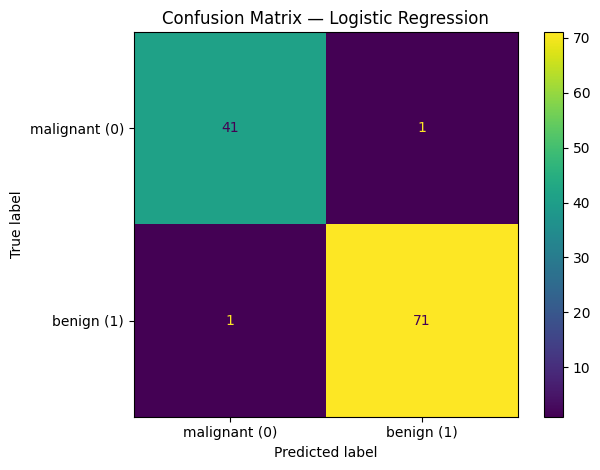

\nDecision Tree
               precision    recall  f1-score   support

malignant (0)       0.85      0.93      0.89        42
   benign (1)       0.96      0.90      0.93        72

     accuracy                           0.91       114
    macro avg       0.90      0.92      0.91       114
 weighted avg       0.92      0.91      0.91       114



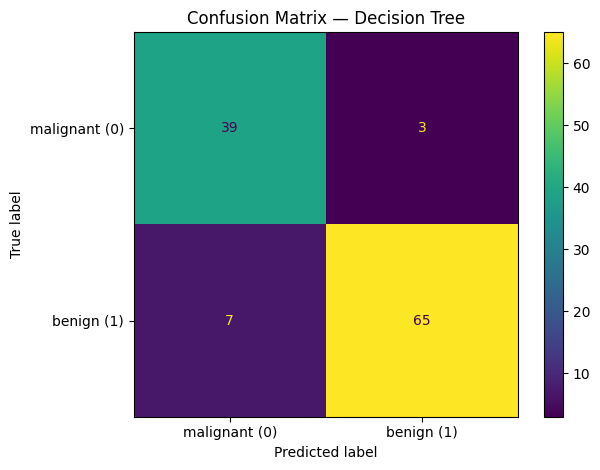

\nK-Nearest Neighbors
               precision    recall  f1-score   support

malignant (0)       0.95      0.93      0.94        42
   benign (1)       0.96      0.97      0.97        72

     accuracy                           0.96       114
    macro avg       0.96      0.95      0.95       114
 weighted avg       0.96      0.96      0.96       114



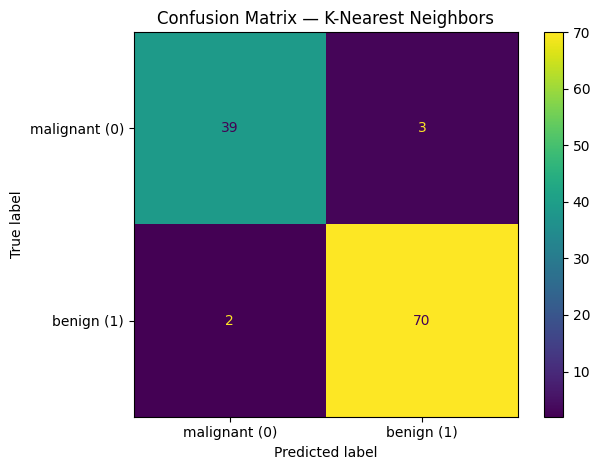

\nGaussian Naive Bayes
               precision    recall  f1-score   support

malignant (0)       0.93      0.90      0.92        42
   benign (1)       0.95      0.96      0.95        72

     accuracy                           0.94       114
    macro avg       0.94      0.93      0.93       114
 weighted avg       0.94      0.94      0.94       114



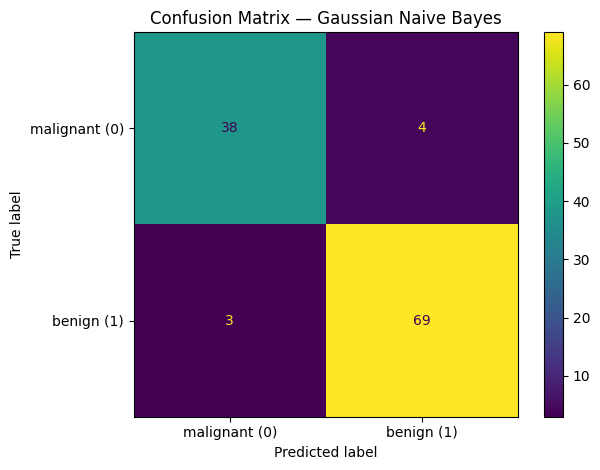

\nSupport Vector Machine
               precision    recall  f1-score   support

malignant (0)       0.98      0.98      0.98        42
   benign (1)       0.99      0.99      0.99        72

     accuracy                           0.98       114
    macro avg       0.98      0.98      0.98       114
 weighted avg       0.98      0.98      0.98       114



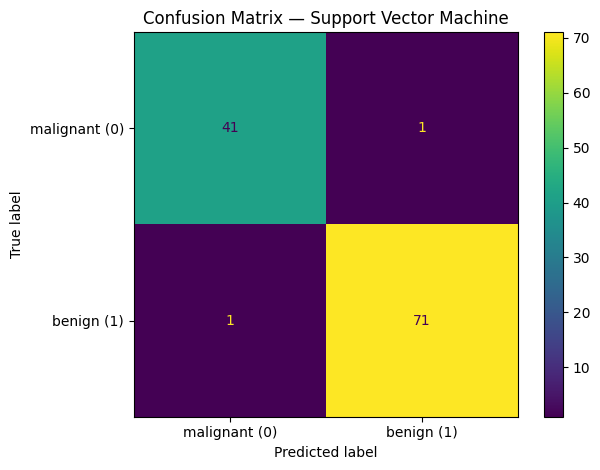

In [8]:
class_names = ["malignant (0)", "benign (1)"]

for model_name, model in fitted_models.items():
    y_pred = model.predict(X_test)
    print(f"\\n{model_name}")
    print(classification_report(y_test, y_pred, target_names=class_names, zero_division=0))
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
    disp.plot(values_format="d")
    plt.title(f"Confusion Matrix — {model_name}")
    plt.tight_layout()
    plt.show()


## 9. Export saved models and artifacts

The scaler is saved inside each applicable scikit-learn pipeline. Separate scaler files are not needed. Exported files include model artifacts, test data, evaluation metrics, and preprocessing metadata.


In [9]:
filename_map = {
    "Logistic Regression": "logistic_regression.joblib",
    "Decision Tree": "decision_tree.joblib",
    "K-Nearest Neighbors": "k_nearest_neighbors.joblib",
    "Gaussian Naive Bayes": "gaussian_naive_bayes.joblib",
    "Support Vector Machine": "support_vector_machine.joblib",
}

for model_name, model in fitted_models.items():
    model_path = MODEL_DIR / filename_map[model_name]
    joblib.dump(model, model_path)
    print("Saved:", model_path)

metrics_path = OUTPUT_DIR / "model_metrics.csv"
metrics_df.to_csv(metrics_path, index=False)

test_export = X_test.copy()
test_export["target"] = y_test
test_path = OUTPUT_DIR / "test_data.csv"
test_export.to_csv(test_path, index=False)

metadata = {
    "dataset": "Breast Cancer Wisconsin (Diagnostic)",
    "target_column": "target",
    "target_mapping": {"0": "malignant", "1": "benign"},
    "feature_columns": list(X.columns),
    "random_state": RANDOM_STATE,
    "test_size": TEST_SIZE,
    "train_rows": int(len(X_train)),
    "test_rows": int(len(X_test))
}
metadata_path = OUTPUT_DIR / "preprocessing_metadata.json"
with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)

print("Saved metrics:", metrics_path)
print("Saved test CSV:", test_path)
print("Saved preprocessing metadata:", metadata_path)


Saved: assignment_outputs/model/logistic_regression.joblib
Saved: assignment_outputs/model/decision_tree.joblib
Saved: assignment_outputs/model/k_nearest_neighbors.joblib
Saved: assignment_outputs/model/gaussian_naive_bayes.joblib
Saved: assignment_outputs/model/support_vector_machine.joblib
Saved metrics: assignment_outputs/model_metrics.csv
Saved test CSV: assignment_outputs/test_data.csv
Saved preprocessing metadata: assignment_outputs/preprocessing_metadata.json


## 10. Validate exported artifacts

In [10]:
print("Export inventory:")
for artifact in sorted(OUTPUT_DIR.rglob("*")):
    if artifact.is_file():
        print(f"{artifact} — {artifact.stat().st_size:,} bytes")

for model_name, filename in filename_map.items():
    restored_model = joblib.load(MODEL_DIR / filename)
    print(model_name, "sample predictions:", restored_model.predict(X_test.iloc[:5]).tolist())

assert len(fitted_models) == 5
assert metrics_df.shape[0] == 5
assert len(test_export) == len(y_test)
print("Artifact validation complete.")


Export inventory:
assignment_outputs/model/decision_tree.joblib — 5,065 bytes
assignment_outputs/model/gaussian_naive_bayes.joblib — 2,535 bytes
assignment_outputs/model/k_nearest_neighbors.joblib — 115,630 bytes
assignment_outputs/model/logistic_regression.joblib — 3,089 bytes
assignment_outputs/model/support_vector_machine.joblib — 28,829 bytes
assignment_outputs/model_metrics.csv — 709 bytes
assignment_outputs/preprocessing_metadata.json — 956 bytes
assignment_outputs/test_data.csv — 24,681 bytes
Logistic Regression sample predictions: [0, 1, 0, 1, 0]
Decision Tree sample predictions: [0, 1, 0, 1, 0]
K-Nearest Neighbors sample predictions: [0, 1, 0, 0, 0]
Gaussian Naive Bayes sample predictions: [0, 1, 0, 1, 0]
Support Vector Machine sample predictions: [0, 1, 0, 1, 0]
Artifact validation complete.
